In [24]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# 0. PENGATURAN AWAL
FILE_XLSX = "3TIF_05_SoftwareDefect (1).xlsx" # Sesuai dengan nama file di Colab kamu
SHEET = "Dataset"
ALPHA = 0.05
SEED = 42

def fp(p):
    return "< 0.001" if p < 0.001 else f"{p:.4f}"

os.makedirs("output/tabel", exist_ok=True)
os.makedirs("output/gambar", exist_ok=True)
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.3})

WARNA = {0: "#4C72B0", 1: "#C44E52"}
LABEL = {0: "Tidak cacat", 1: "Cacat"}
print("Sel 1: Library dan Pengaturan berhasil dimuat!")

Sel 1: Library dan Pengaturan berhasil dimuat!


In [25]:
# 1. MEMBACA & MEMERIKSA DATA
df = pd.read_excel(FILE_XLSX, sheet_name=SHEET, na_values=["NA"])
print("=" * 70); print("1. PEMERIKSAAN DATA"); print("=" * 70)
print("Ukuran data awal (baris, kolom):", df.shape)

# Menghapus anomali (nilai desimal pada LOC/VG)
anomali = df[(df[["LOC", "VG", "EVG", "IVG"]] % 1 != 0).any(axis=1)]
if len(anomali) > 0:
    df = df.drop(anomali.index).reset_index(drop=True)

VAR = ["LOC", "VG"]
cacat = df[df["Cacat"] == 1]
tidak = df[df["Cacat"] == 0]
n1, n0 = len(cacat), len(tidak)

print(f"Modul cacat = {n1}, tidak cacat = {n0}")
print("\nSel 2: Data bersih dan siap dianalisis!")

1. PEMERIKSAAN DATA
Ukuran data awal (baris, kolom): (5000, 7)
Modul cacat = 978, tidak cacat = 4021

Sel 2: Data bersih dan siap dianalisis!



2. STATISTIKA DESKRIPTIF
                        n    Mean  Median      Std  Min     Max  Skewness
LOC | Tidak cacat  4021.0  32.925    20.0   45.241  1.0   706.0     5.195
LOC | Cacat         978.0  76.067    45.0  115.208  4.0  1882.0     8.530
VG | Tidak cacat   4021.0   4.974     3.0    6.517  1.0    97.0     4.590
VG | Cacat          978.0  11.064     5.5   19.910  1.0   286.0     8.166


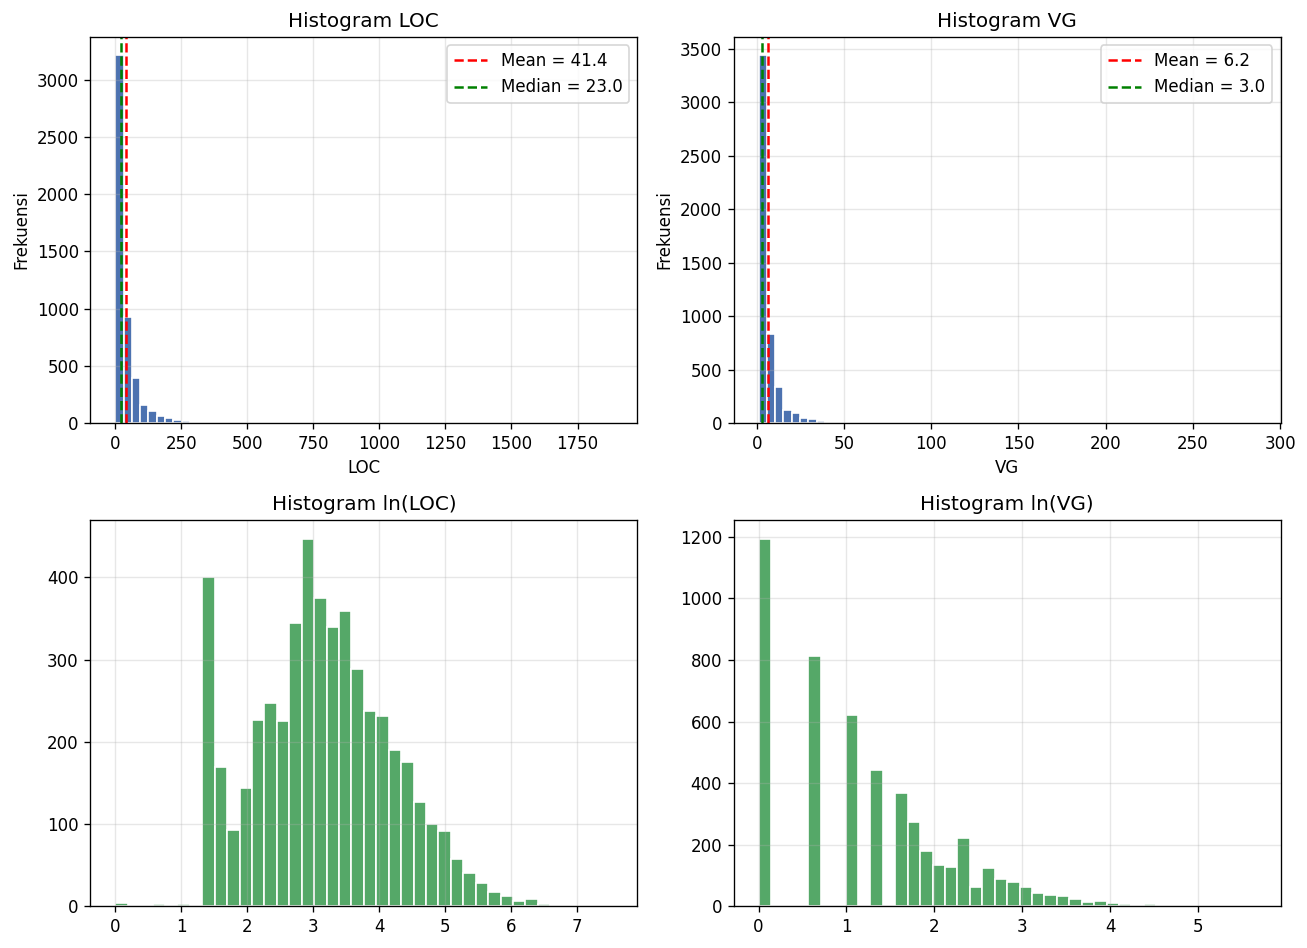

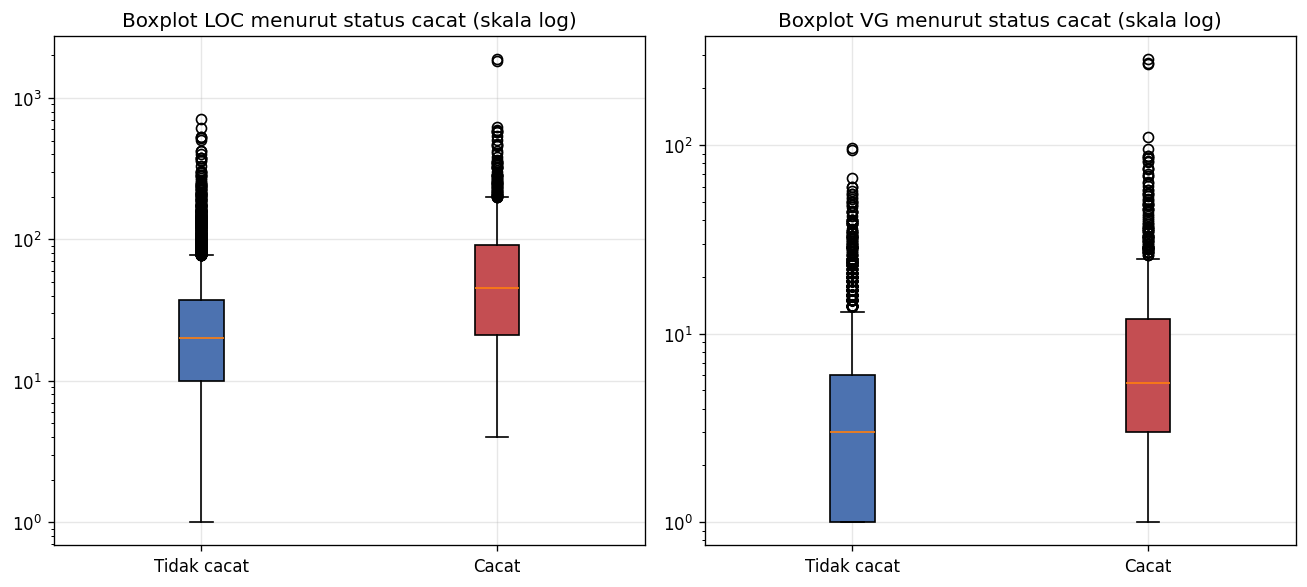

In [30]:
# 2. STATISTIKA DESKRIPTIF
def ringkas(x):
    x = x.dropna()
    return pd.Series({
        "n": len(x), "Mean": x.mean(), "Median": x.median(), "Std": x.std(ddof=1),
        "Min": x.min(), "Max": x.max(), "Skewness": stats.skew(x)
    })

print("\n" + "=" * 70); print("2. STATISTIKA DESKRIPTIF"); print("=" * 70)
desk_grup = pd.concat({f"{v} | {LABEL[g]}": ringkas(d[v]) for v in VAR for g, d in [(0, tidak), (1, cacat)]}, axis=1).T
print(desk_grup.round(3).to_string())

# Grafik 1: Histogram
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for j, v in enumerate(VAR):
    ax[0, j].hist(df[v], bins=60, color="#4C72B0", edgecolor="white")
    ax[0, j].axvline(df[v].mean(), color="red", ls="--", label=f"Mean = {df[v].mean():.1f}")
    ax[0, j].axvline(df[v].median(), color="green", ls="--", label=f"Median = {df[v].median():.1f}")
    ax[0, j].set_title(f"Histogram {v}")
    ax[0, j].set_xlabel(v); ax[0, j].set_ylabel("Frekuensi"); ax[0, j].legend()
    ax[1, j].hist(np.log(df[v]), bins=40, color="#55A868", edgecolor="white")
    ax[1, j].set_title(f"Histogram ln({v})")
plt.tight_layout(); plt.show()

# Grafik 2: Boxplot
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for j, v in enumerate(VAR):
    data = [tidak[v], cacat[v]]
    bp = ax[j].boxplot(data, tick_labels=["Tidak cacat", "Cacat"], patch_artist=True, showfliers=True)
    for patch, g in zip(bp["boxes"], [0, 1]):
        patch.set_facecolor(WARNA[g])
    ax[j].set_yscale("log")
    ax[j].set_title(f"Boxplot {v} menurut status cacat (skala log)")
plt.tight_layout(); plt.show()


3. UJI NORMALITAS DAN HOMOGENITAS VARIANS
Variabel Skala  Shapiro W  p Shapiro   Kesimpulan
     LOC  Asli     0.4608  8.756e-82 Tidak normal
     LOC    ln      0.985   1.21e-22 Tidak normal
      VG  Asli     0.4068  6.978e-84 Tidak normal
      VG    ln     0.9342  2.033e-42 Tidak normal


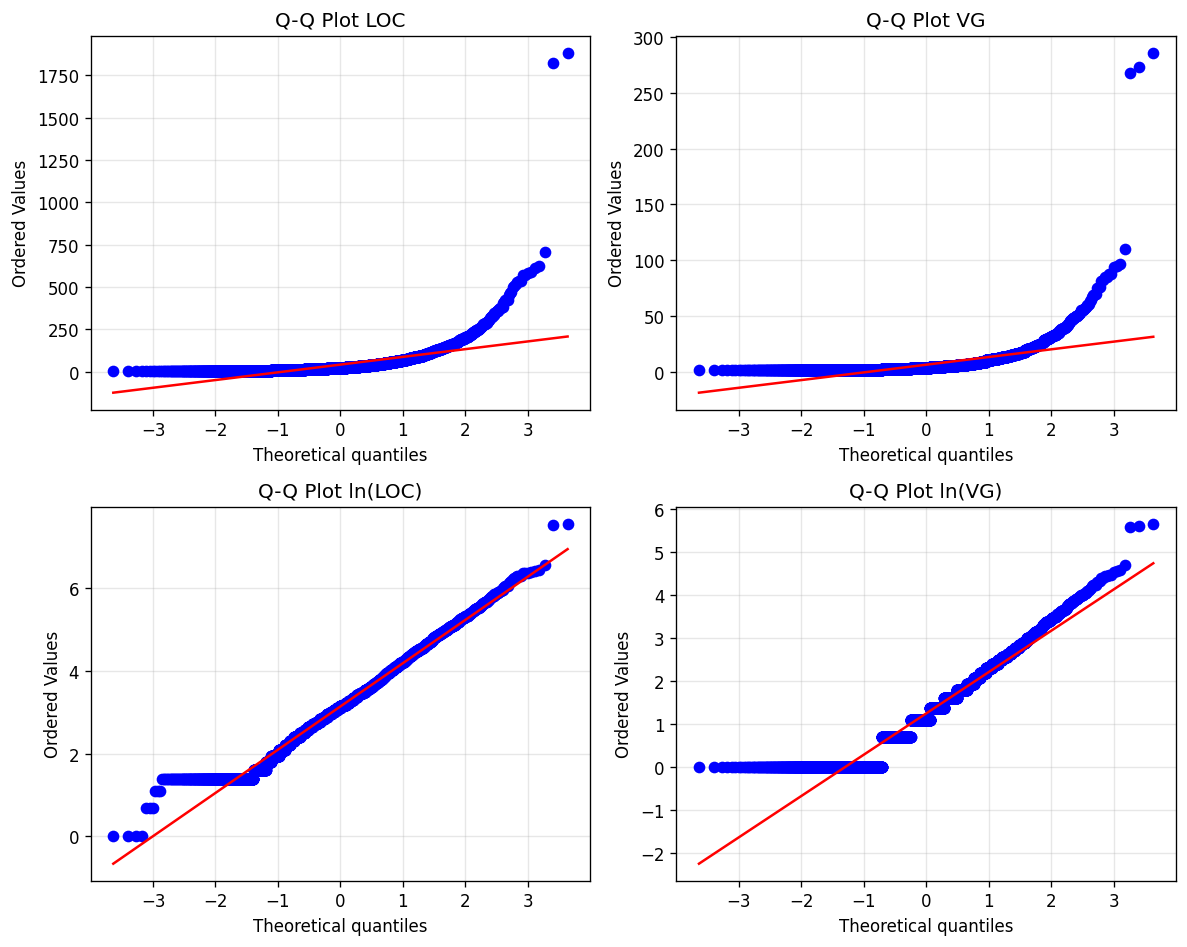

In [27]:
# 3. UJI NORMALITAS DAN HOMOGENITAS VARIANS
print("\n" + "=" * 70); print("3. UJI NORMALITAS DAN HOMOGENITAS VARIANS"); print("=" * 70)
hasil_norm = []
for v in VAR:
    for nama, x in [("Asli", df[v]), ("ln", np.log(df[v]))]:
        sw = stats.shapiro(x.sample(4999, random_state=SEED) if len(x) > 5000 else x)
        hasil_norm.append([v, nama, sw.statistic, sw.pvalue, "Normal" if sw.pvalue > ALPHA else "Tidak normal"])

norm_df = pd.DataFrame(hasil_norm, columns=["Variabel", "Skala", "Shapiro W", "p Shapiro", "Kesimpulan"])
print(norm_df.to_string(index=False, float_format=lambda a: f"{a:.4g}"))

# Grafik 3: Q-Q Plot
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
for j, v in enumerate(VAR):
    stats.probplot(df[v], dist="norm", plot=ax[0, j]); ax[0, j].set_title(f"Q-Q Plot {v}")
    stats.probplot(np.log(df[v]), dist="norm", plot=ax[1, j]); ax[1, j].set_title(f"Q-Q Plot ln({v})")
plt.tight_layout(); plt.show()


4. DISTRIBUSI PROBABILITAS
Proporsi modul cacat (p) = 0.1956
Jika diperiksa 20 modul acak, peluang minimal 1 modul cacat = 0.9871


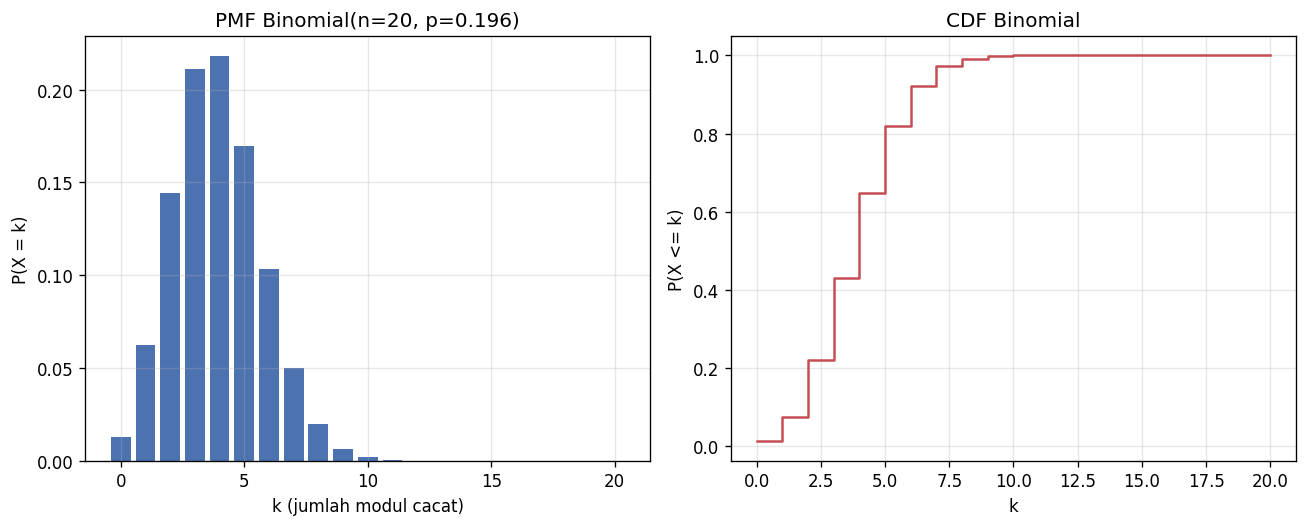

In [28]:
# 4. DISTRIBUSI PROBABILITAS
print("\n" + "=" * 70); print("4. DISTRIBUSI PROBABILITAS"); print("=" * 70)
p_hat = n1 / len(df)
n_uji = 20
print(f"Proporsi modul cacat (p) = {p_hat:.4f}")
print(f"Jika diperiksa {n_uji} modul acak, peluang minimal 1 modul cacat = {1 - stats.binom(n_uji, p_hat).pmf(0):.4f}")

tabel_binom = pd.DataFrame({
    "k": range(n_uji + 1),
    "P(X=k)": stats.binom(n_uji, p_hat).pmf(range(n_uji + 1)),
    "P(X<=k)": stats.binom(n_uji, p_hat).cdf(range(n_uji + 1))
})

# Grafik 4: Binomial
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].bar(tabel_binom["k"], tabel_binom["P(X=k)"], color="#4C72B0")
ax[0].set_title(f"PMF Binomial(n={n_uji}, p={p_hat:.3f})")
ax[0].set_xlabel("k (jumlah modul cacat)"); ax[0].set_ylabel("P(X = k)")
ax[1].step(tabel_binom["k"], tabel_binom["P(X<=k)"], where="post", color="#C44E52")
ax[1].set_title("CDF Binomial"); ax[1].set_xlabel("k"); ax[1].set_ylabel("P(X <= k)")
plt.tight_layout(); plt.show()


5. STATISTIKA INFERENSIAL
Uji Beda LOC: U = 2797722, p-value = 7.93e-94 -> Signifikan (Beda)
Uji Beda VG: U = 2624678, p-value = 9.747e-61 -> Signifikan (Beda)

Korelasi Spearman (LOC & VG): rho = 0.8115, p-value = < 0.001


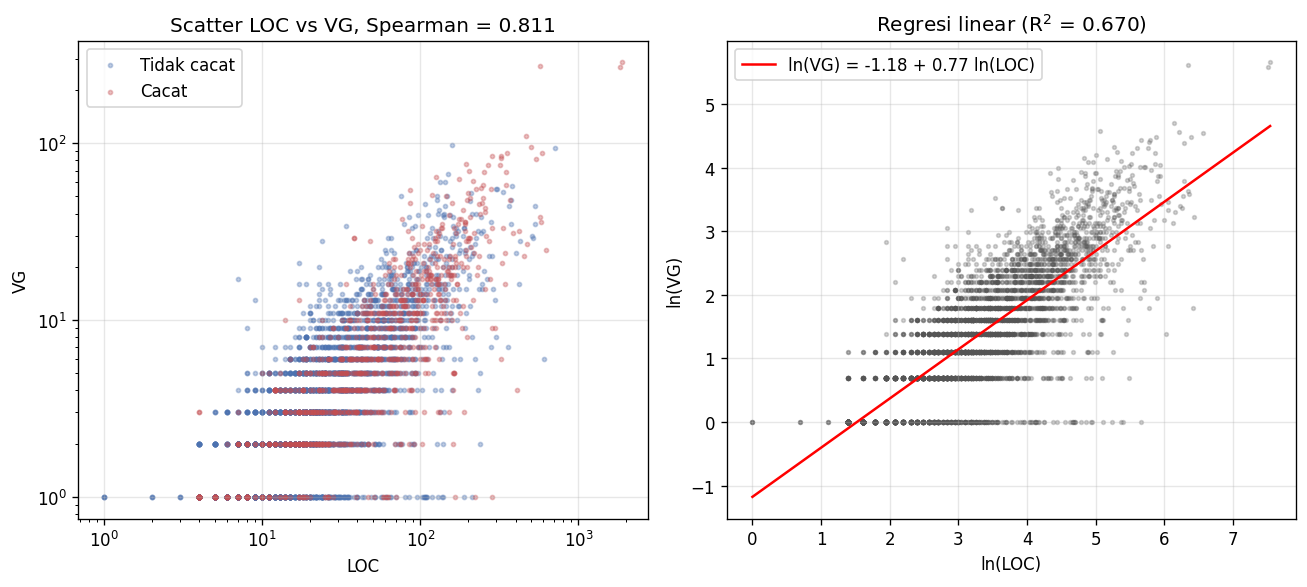

In [29]:
# 5. STATISTIKA INFERENSIAL
print("\n" + "=" * 70); print("5. STATISTIKA INFERENSIAL"); print("=" * 70)

# Uji Beda Mann-Whitney
for v in VAR:
    mw = stats.mannwhitneyu(cacat[v], tidak[v], alternative="two-sided")
    print(f"Uji Beda {v}: U = {mw.statistic:.0f}, p-value = {mw.pvalue:.4g} -> "
          f"{'Signifikan (Beda)' if mw.pvalue < ALPHA else 'Tidak Signifikan'}")

# Korelasi
sp_r, sp_p = stats.spearmanr(df["LOC"], df["VG"])
print(f"\nKorelasi Spearman (LOC & VG): rho = {sp_r:.4f}, p-value = {fp(sp_p)}")

# Grafik 5: Scatter & Regresi
reg = stats.linregress(np.log(df["LOC"]), np.log(df["VG"]))
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for g in [0, 1]:
    d_ = df[df["Cacat"] == g]
    ax[0].scatter(d_["LOC"], d_["VG"], s=6, alpha=0.35, color=WARNA[g], label=LABEL[g])
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("LOC"); ax[0].set_ylabel("VG"); ax[0].legend()
ax[0].set_title(f"Scatter LOC vs VG, Spearman = {sp_r:.3f}")

xs = np.linspace(np.log(df["LOC"]).min(), np.log(df["LOC"]).max(), 100)
ax[1].scatter(np.log(df["LOC"]), np.log(df["VG"]), s=5, alpha=0.25, color="#555555")
ax[1].plot(xs, reg.intercept + reg.slope * xs, color="red", label=f"ln(VG) = {reg.intercept:.2f} + {reg.slope:.2f} ln(LOC)")
ax[1].set_xlabel("ln(LOC)"); ax[1].set_ylabel("ln(VG)")
ax[1].set_title(f"Regresi linear (R$^2$ = {reg.rvalue**2:.3f})"); ax[1].legend()
plt.tight_layout(); plt.show()